# Importar as bibliotecas e carregar o dataset

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Localizar o projeto a partir da raiz ou da pasta notebooks
raiz = Path.cwd()

if raiz.name == "notebooks":
    raiz = raiz.parent

caminho = raiz / "data" / "raw" / "payflow_credit_risk.csv"

# Carregar os dados originais
df = pd.read_csv(caminho)

print(f"Clientes: {df.shape[0]}")
print(f"Colunas: {df.shape[1]}")

display(df.head())

Clientes: 5000
Colunas: 23


,id_cliente,idade,renda_mensal,tempo_emprego_anos,autonomo,score_credito,valor_solicitado,prazo_meses,juros_mensal_pct,qtde_cartoes,...,dias_atraso_max_12m,reclamacoes_6m,possui_avalista,canal_aquisicao,regiao,tipo_produto,parcelas_pagas_ate_3m,atraso_primeira_parcela_dias,status_apos_90d,default_90d
0,1,22,2639.75,2.718888,0,617.0,2619.14,12,3.96,3,...,0,0,0,site,Sul,emprestimo_pessoal,0,29,default,1
1,2,59,2482.34,10.785992,0,619.0,9101.21,36,3.37,2,...,0,0,0,app,Sudeste,cartao,2,10,em_dia,0
2,3,52,6230.69,9.547608,0,665.0,13258.67,48,3.12,0,...,0,0,0,loja,Sudeste,cartao,2,0,em_dia,0
3,4,41,6469.45,4.287084,0,676.0,1407.28,12,1.52,2,...,90,1,0,parceiro,Sudeste,emprestimo_pessoal,3,0,em_dia,0
4,5,40,2343.04,0.000000,0,671.0,2647.92,48,3.07,1,...,15,0,0,app,Nordeste,bnpl,2,10,em_atraso_leve,0


# Analisar a inadimplência por faixa de score

Queremos investigar se clientes com scores menores apresentam maior frequência de default.

In [2]:
# Criar faixas de score de crédito
df["faixa_score"] = pd.cut(
    df["score_credito"],
    bins=[299, 500, 600, 700, 800, 900],
    labels=[
        "300-500",
        "501-600",
        "601-700",
        "701-800",
        "801-900"
    ]
)

# Calcular a taxa de inadimplência por faixa
inadimplencia_score = (
    df.groupby("faixa_score", observed=True)
    .agg(
        clientes=("default_90d", "size"),
        taxa_default=("default_90d", "mean")
    )
    .reset_index()
)

inadimplencia_score["taxa_default"] *= 100

display(inadimplencia_score)

,faixa_score,clientes,taxa_default
0,300-500,191,19.371728
1,501-600,1143,15.923010
2,601-700,2239,11.344350
3,701-800,1208,9.437086
4,801-900,219,10.045662


Divide os clientes em faixas de score de crédito e calcula a taxa de inadimplência de cada faixa.

# Visualizar a relação entre score e inadimplência
Vamos criar um gráfico de barras com o percentual de clientes inadimplentes em cada faixa de score.

Facilita identificar diferenças de risco e possíveis tendências.

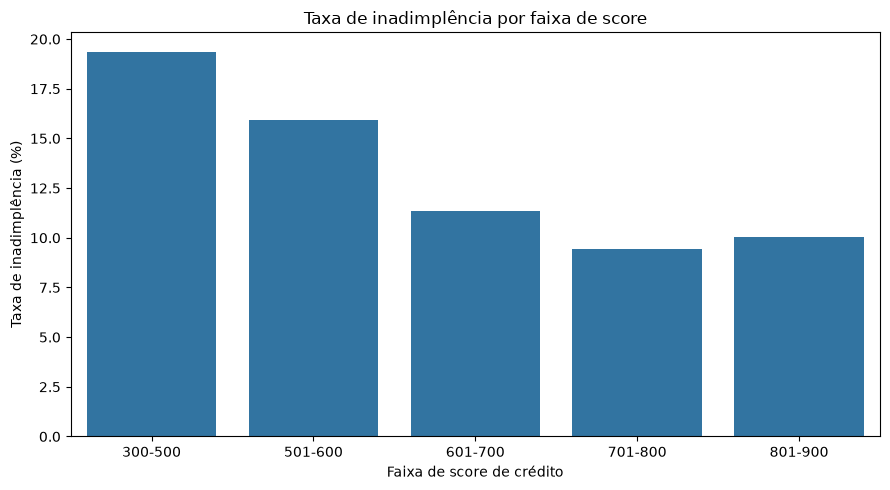

In [3]:
plt.figure(figsize=(9, 5))

sns.barplot(
    data=inadimplencia_score,
    x="faixa_score",
    y="taxa_default"
)

plt.title("Taxa de inadimplência por faixa de score")
plt.xlabel("Faixa de score de crédito")
plt.ylabel("Taxa de inadimplência (%)")

plt.tight_layout()
plt.show()

Caso as faixas de score mais baixas apresentem maior taxa de default, teremos evidência de uma associação entre score e inadimplência. Isso não comprova causalidade.

# Analisar inadimplência por tipo de produto
Vamos calcular a quantidade de clientes e a taxa de inadimplência para empréstimo pessoal, cartão e BNPL.

Informa que a PayFlow trabalha com três produtos. Precisamos verificar se apresentam comportamentos de risco diferentes.

,tipo_produto,clientes,taxa_default
0,bnpl,736,15.760870
1,cartao,1799,12.006670
2,emprestimo_pessoal,2465,11.237323


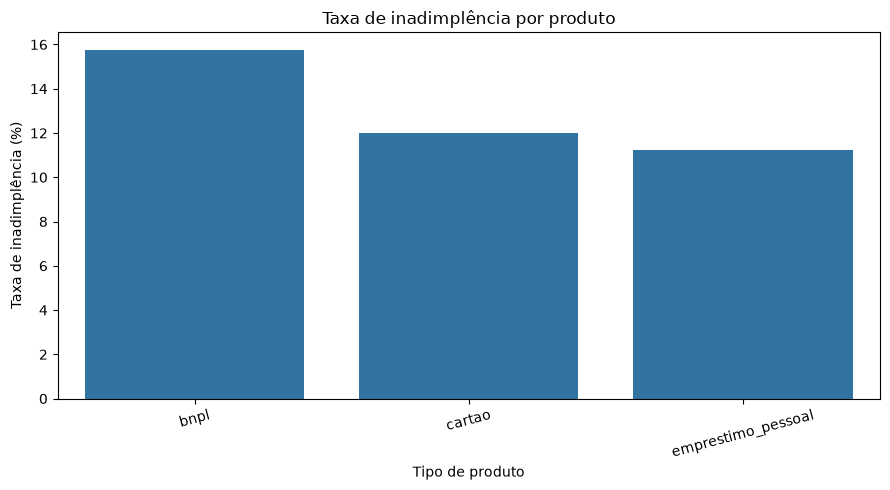

In [4]:
inadimplencia_produto = (
    df.groupby("tipo_produto")
    .agg(
        clientes=("default_90d", "size"),
        taxa_default=("default_90d", "mean")
    )
    .reset_index()
)

inadimplencia_produto["taxa_default"] *= 100

display(inadimplencia_produto)

plt.figure(figsize=(9, 5))

sns.barplot(
    data=inadimplencia_produto,
    x="tipo_produto",
    y="taxa_default"
)

plt.title("Taxa de inadimplência por produto")
plt.xlabel("Tipo de produto")
plt.ylabel("Taxa de inadimplência (%)")
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

# Verificar a associação entre variáveis numéricas
Calcula correlações de Pearson entre variáveis numéricas selecionadas e apresenta uma matriz visual.

Queremos identificar relações lineares que mereçam investigação, inclusive possíveis associações com default_90d.

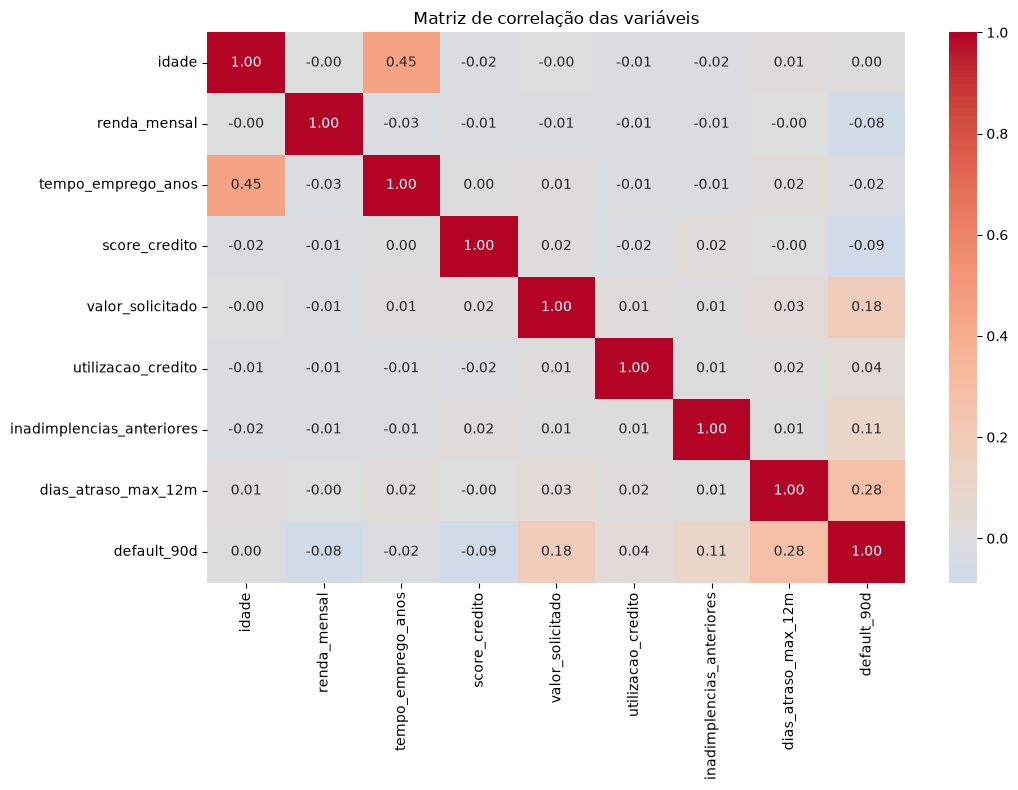

In [5]:
# Selecionar variáveis relevantes para análise
variaveis = [
    "idade",
    "renda_mensal",
    "tempo_emprego_anos",
    "score_credito",
    "valor_solicitado",
    "utilizacao_credito",
    "inadimplencias_anteriores",
    "dias_atraso_max_12m",
    "default_90d"
]

# Calcular correlação
correlacoes = df[variaveis].corr(method="pearson")

# Gerar matriz visual
plt.figure(figsize=(11, 8))

sns.heatmap(
    correlacoes,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0
)

plt.title("Matriz de correlação das variáveis")
plt.tight_layout()
plt.show()

Variáveis com baixa correlação de Pearson ainda podem ser úteis para modelos que capturam relações não lineares. Também excluímos dessa análise os identificadores e as variáveis conhecidas de leakage.

# Analisar renda mensal e inadimplência
Queremos verificar se clientes com rendas diferentes apresentam frequências distintas de default.

Divide os clientes em faixas de renda por quartis e calcula a taxa de inadimplência de cada grupo.

In [6]:
# Criar faixas de renda por quartis
df["faixa_renda"] = pd.qcut(
    df["renda_mensal"],
    q=4,
    duplicates="drop"
)

# Calcular a inadimplência por faixa
analise_renda = (
    df.groupby("faixa_renda", observed=True)
    .agg(
        clientes=("default_90d", "size"),
        taxa_default=("default_90d", "mean")
    )
    .reset_index()
)

analise_renda["taxa_default"] *= 100

display(analise_renda)

,faixa_renda,clientes,taxa_default
0,"(799.999, 2136.475]",1202,18.136439
1,"(2136.475, 3496.405]",1202,11.730449
2,"(3496.405, 5863.252]",1202,10.066556
3,"(5863.252, 35000.0]",1202,8.153078


Observação: clientes sem informação de renda não aparecem nesses grupos. Vamos analisar os valores ausentes separadamente.

# Analisar o histórico de atrasos
O histórico de pagamentos pode conter informações relevantes para compreender o risco futuro.

Compara a taxa de inadimplência entre clientes agrupados pelo maior atraso registrado nos últimos 12 meses.

In [7]:
# Criar faixas de atraso anteriores à concessão
df["faixa_atraso"] = pd.cut(
    df["dias_atraso_max_12m"],
    bins=[-1, 0, 30, 60, 90, float("inf")],
    labels=[
        "Sem atraso",
        "1-30 dias",
        "31-60 dias",
        "61-90 dias",
        "Mais de 90 dias"
    ]
)

analise_atraso = (
    df.groupby("faixa_atraso", observed=True)
    .agg(
        clientes=("default_90d", "size"),
        taxa_default=("default_90d", "mean")
    )
    .reset_index()
)

analise_atraso["taxa_default"] *= 100

display(analise_atraso)

,faixa_atraso,clientes,taxa_default
0,Sem atraso,3018,8.117959
1,1-30 dias,1491,12.608987
2,31-60 dias,280,26.428571
3,61-90 dias,148,41.891892
4,Mais de 90 dias,63,63.492063


Essa análise utiliza dias_atraso_max_12m, que representa o histórico anterior. Não devemos confundi-la com atraso_primeira_parcela_dias, que é uma variável de data leakage.

# Analisar a utilização de crédito
Queremos investigar se a utilização mais elevada do crédito está associada a uma frequência maior de inadimplência.

Compara a inadimplência entre grupos com diferentes percentuais de utilização do limite de crédito.

In [8]:
# Criar faixas de utilização do crédito
df["faixa_utilizacao"] = pd.cut(
    df["utilizacao_credito"],
    bins=[-0.001, 0.25, 0.50, 0.75, 1.0],
    labels=[
        "0-25%",
        "25-50%",
        "50-75%",
        "75-100%"
    ]
)

# Calcular taxa de default
analise_utilizacao = (
    df.groupby("faixa_utilizacao", observed=True)
    .agg(
        clientes=("default_90d", "size"),
        taxa_default=("default_90d", "mean")
    )
    .reset_index()
)

analise_utilizacao["taxa_default"] *= 100

display(analise_utilizacao)

,faixa_utilizacao,clientes,taxa_default
0,0-25%,1850,11.405405
1,25-50%,2239,12.058955
2,50-75%,808,13.861386
3,75-100%,103,15.533981


#### Visualizar os resultados

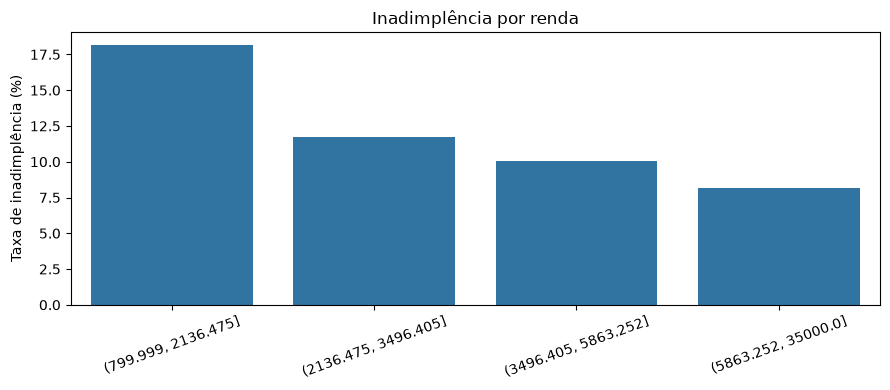

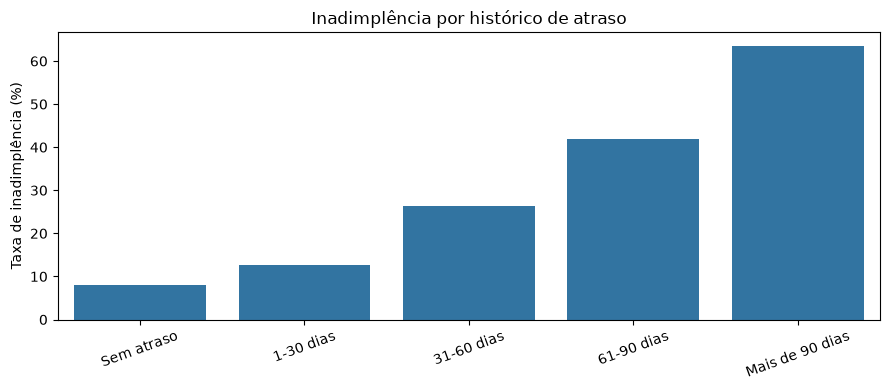

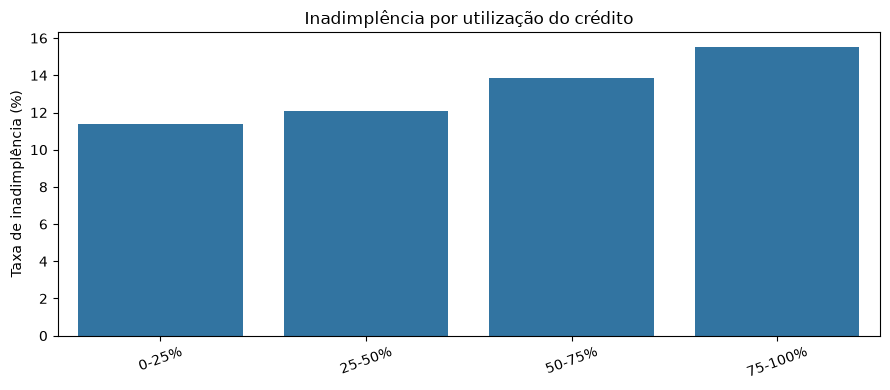

In [9]:
analises = [
    (analise_renda, "faixa_renda", "Inadimplência por renda"),
    (analise_atraso, "faixa_atraso", "Inadimplência por histórico de atraso"),
    (analise_utilizacao, "faixa_utilizacao", "Inadimplência por utilização do crédito")
]

for dados, coluna, titulo in analises:
    plt.figure(figsize=(9, 4))

    sns.barplot(
        data=dados,
        x=coluna,
        y="taxa_default"
    )

    plt.title(titulo)
    plt.xlabel("")
    plt.ylabel("Taxa de inadimplência (%)")
    plt.xticks(rotation=20)
    plt.tight_layout()
    plt.show()

# Verificar se a ausência de renda está associada ao default
Dados ausentes também podem apresentar padrões relevantes. Antes de escolher uma técnica de imputação, é importante compreender como esses casos se comportam.

Compara clientes com e sem renda declarada.

In [10]:
# Criar indicador de renda ausente
df["renda_ausente"] = df["renda_mensal"].isna()

# Comparar grupos
analise_ausentes = (
    df.groupby("renda_ausente")
    .agg(
        clientes=("default_90d", "size"),
        taxa_default=("default_90d", "mean")
    )
)

analise_ausentes["taxa_default"] *= 100

display(analise_ausentes)

,clientes,taxa_default
renda_ausente,,
False,4808,12.021631
True,192,16.145833


# Tabela consolidada
Facilita comparar os resultados, preparar o relatório e identificar quais relações merecem investigação posterior.

Reúne as principais análises da EDA em uma única tabela, mostrando a quantidade de clientes e a taxa de inadimplência por grupo.

In [11]:
# Reunir as análises feitas anteriormente
analises_eda = {
    "Score de crédito": inadimplencia_score,
    "Tipo de produto": inadimplencia_produto,
    "Renda mensal": analise_renda,
    "Histórico de atraso": analise_atraso,
    "Utilização de crédito": analise_utilizacao
}

resultados = []

for nome_analise, tabela in analises_eda.items():
    coluna_grupo = tabela.columns[0]

    for _, linha in tabela.iterrows():
        resultados.append({
            "analise": nome_analise,
            "grupo": str(linha[coluna_grupo]),
            "clientes": int(linha["clientes"]),
            "taxa_default_pct": round(
                float(linha["taxa_default"]), 2
            )
        })

resumo_eda = pd.DataFrame(resultados)

display(resumo_eda)

,analise,grupo,clientes,taxa_default_pct
0,Score de crédito,300-500,191,19.37
1,Score de crédito,501-600,1143,15.92
2,Score de crédito,601-700,2239,11.34
3,Score de crédito,701-800,1208,9.44
4,Score de crédito,801-900,219,10.05
5,Tipo de produto,bnpl,736,15.76
6,Tipo de produto,cartao,1799,12.01
7,Tipo de produto,emprestimo_pessoal,2465,11.24
8,Renda mensal,"(799.999, 2136.475]",1202,18.14
9,Renda mensal,"(2136.475, 3496.405]",1202,11.73


#### Tabelas da EDA

In [12]:
# Definir pasta de saída
pasta_tabelas = raiz / "reports" / "tables"
pasta_tabelas.mkdir(parents=True, exist_ok=True)

# Salvar resumo consolidado
resumo_eda.to_csv(
    pasta_tabelas / "resumo_eda.csv",
    index=False,
    encoding="utf-8-sig"
)

# Salvar análises individuais
for nome, tabela in analises_eda.items():
    nome_arquivo = (
        nome.lower()
        .replace(" ", "_")
        .replace("é", "e")
        .replace("ç", "c")
        .replace("ã", "a")
    )

    tabela.to_csv(
        pasta_tabelas / f"{nome_arquivo}.csv",
        index=False,
        encoding="utf-8-sig"
    )

print("Tabelas exportadas com sucesso!")

Tabelas exportadas com sucesso!
